# Week 3 · Programme flow: decisions and loops

**CM3801 · CMT309/509 · CMT124** · shared session · Thursday 22 October 2026

Until now every line of your programs ran exactly once, from top to bottom. Today your programs start to **decide** what to do and to **repeat** work, and last week's lists and dictionaries become something you can walk through item by item.

By the end of today you can write Boolean expressions, choose between blocks of code with `if`/`elif`/`else`, repeat code with `while` and `for` (with `break`, `continue` and `range`), loop over strings, lists and dictionaries, write list comprehensions, and turn an idea into pseudocode and then into a program.

Today has three teaching parts and a lab: **Hour 1** making decisions · **Hour 2** repeating · **Hour 3** looping over data and designing a program · **Lab** Guess My Number.

Some cells ask you to type something (`input()`): type your answer in the box that appears and press Enter.

## Hour 1 · Making decisions

### Questions with a yes/no answer

A **Boolean expression** is an expression whose value is `True` or `False`. Read it as a yes/no question: *"Is it warmer than 15 °C?"*

* An `if` statement uses a Boolean expression to decide **which** code runs next.
* A loop uses one to decide **when to stop** (Hour 2).

**Predict:** which of the three lines below print `True`?

In [ ]:
temp = 16.0     # today's maximum, °C
rain = 2.4      # today's rainfall, mm
print(temp > 15)
print(temp > 15 and rain == 0)
print(temp > 15 or rain == 0)

Only the first and the last. `and` needs **both** sides to be true; `or` needs **at least one**.

### Four kinds of conditional operator

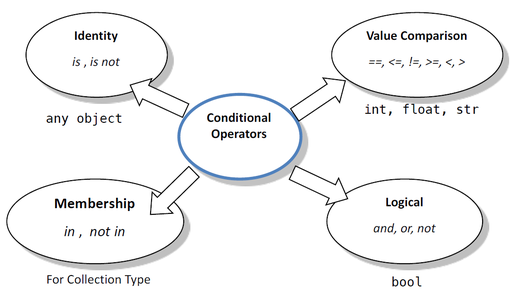

| Comparison | Meaning | Example | Value |
|---|---|---|---|
| `==` | equal to | `5 == 5` | `True` |
| `!=` | not equal to | `8 != 7` | `True` |
| `>` / `<` | larger / less than | `6 > 10` | `False` |
| `>=` / `<=` | larger / less than or equal | `5 <= 78` | `True` |

Remember from Week 1: `=` **assigns** a value, `==` **compares** two values.

**Predict:** with `x = 10`, what does `0 < x < 20` give? And after `x = 25`?

In [ ]:
x = 10
print(0 < x and x < 20)
print(0 < x < 20)          # a chained comparison: reads like maths
x = 25
print(0 < x < 20)

`0 < x < 20` means exactly `0 < x and x < 20`, so it is `True` for 10 and `False` for 25.

### Logic: `and`, `or`, `not`

| `A` | `B` | `A and B` | `A or B` | `not A` |
|---|---|---|---|---|
| `True` | `True` | `True` | `True` | `False` |
| `True` | `False` | `False` | `True` | `False` |
| `False` | `True` | `False` | `True` | `True` |
| `False` | `False` | `False` | `False` | `True` |

When you combine several conditions, brackets make them easier to read: `(0 < x < 3) and (6 < y < 8)`.

**Quick check:** with `temp = 16.0` and `rain = 2.4`, is `not (temp > 15 and rain == 0)` **A** `True` or **B** `False`?

<details><summary>Answer</summary>

**A** `True`. The bracket is `True and False`, which is `False`, and `not False` is `True`. In words: "it is *not* a warm, dry day".

</details>

### Identity and membership

* `is` / `is not` ask whether two names refer to the **same object** (the Week 2 alias question).
* `in` / `not in` ask whether an item belongs to a collection: a string, list, tuple or dictionary.

In [ ]:
a = [1, 2, 3]
b = a
c = a.copy()
print(b is a, c is a, c == a)
print("H" in "Hello", "oo" not in "Hello")
print("Cardiff" in {"Cardiff": 362400, "Swansea": 238500})

`c == a` is `True` (same values) but `c is a` is `False` (a different list). Use `==` to compare values. And, as in Week 2, `in` on a dictionary checks the **keys**.

### `if`, `elif`, `else`

```python
if condition_1:
    block_1
elif condition_2:        # optional, as many as you need
    block_2
else:                    # optional: runs if no condition was True
    else_block
```

Python tests the conditions from top to bottom and runs the block of the **first** one that is `True`. At most one block runs.

In [ ]:
# ✍️ Type along: a simple password program

<details><summary>Code from class</summary>

```python
password = input("Enter your password: ")
if password == "secret":
    print("Access Granted")
else:
    print("Access Denied")
```

Run it twice: once with the right password, once with a wrong one.

</details>

A slightly better version has **three** outcomes.

**Before we run this:** what will you see if you type `Secret`, with a capital S?

In [ ]:
password = input("Enter your password: ")
if password == "supersecret":
    print("Administrator Access Granted")
elif password == "secret":
    print("Guest Access Granted")
else:
    print("Access Denied")

`Access Denied`: string comparison is case-sensitive, so `"Secret" == "secret"` is `False`. (A Week 1 string method, `.lower()`, would fix that.)

### Indentation marks the block

How does Python know where the `else` block ends? By **indentation**: the spaces at the start of a line.

* All lines of a block are indented by the same amount; the first line that is not indented ends the block.
* Use **4 spaces** per level (the PEP 8 style guide). Colab indents automatically after a line ending in `:`.

Indentation errors are more common than slugs in British gardens.

**Predict:** what does this cell print?

In [ ]:
t = False                     # main code, no indentation
if t:                         # the header of the if statement
    print("Hello Class!")     # code block
    print("Hello World!")     # code block
print("Not part of the if block")

Only the last line: the two indented lines belong to the `if` and are skipped because `t` is `False`. Change `t` to `True` and run it again.

The next cell forgets to indent. What will Python say?

In [ ]:
# ⚠️ This cell raises an error on purpose
t = True
if t:
print("Hello Class!")

`IndentationError: expected an indented block`: after a line ending in `:` Python needs at least one indented line.

**Quick check:** which branch runs? **A** `hot` · **B** `warm` · **C** `warm` and `mild` · **D** `mild`

In [ ]:
temp = 18
if temp > 25:
    print("hot")
elif temp > 15:
    print("warm")
elif temp > 5:
    print("mild")
else:
    print("cold")

**B**. `18 > 15` is the first true condition, so `warm` is printed and the rest is skipped, even though `18 > 5` is also true.

Now set `temp = 5` and predict the output before running it again. (Is 5 larger than 5?)

**Your turn:** grade banding. Print the classification of `mark` using these bands, then test your code with 70, 69.5 and 39.

| Mark | Classification |
|---|---|
| 70 and above | First |
| 60 to below 70 | Upper second (2:1) |
| 50 to below 60 | Lower second (2:2) |
| 40 to below 50 | Third |
| below 40 | Fail |

In [ ]:
mark = 64
# your code here

<details><summary>Answer</summary>

```python
mark = 64
if mark >= 70:
    grade = "First"
elif mark >= 60:
    grade = "Upper second (2:1)"
elif mark >= 50:
    grade = "Lower second (2:2)"
elif mark >= 40:
    grade = "Third"
else:
    grade = "Fail"
print(f"Mark {mark}: {grade}")
```

**Order matters.** Because only the first true branch runs, each `elif` can assume the conditions above it were false: that is why `mark >= 60` is enough for the 2:1 band. If you tested `mark >= 40` first, every pass would come out as a Third.

**Challenge:** print `Invalid mark` if `mark` is not between 0 and 100. (`not 0 <= mark <= 100`)

</details>

### Takeaways: making decisions

* A Boolean expression answers a yes/no question; `and`, `or` and `not` combine them, and comparisons can be chained: `0 < x < 20`.
* `==` compares values; `is` checks for the same object; `in` checks membership (the keys, for a dictionary).
* `if`/`elif`/`else` runs the block of the **first** true condition, and at most one block.
* Indentation (4 spaces) defines a block; a missing indent is an `IndentationError`.

## Hour 2 · Repeating

### Redirecting the flow

A program normally runs from top to bottom (left). In Hour 1, `if`/`elif` let the flow **skip** blocks (right). A **loop** sends the flow **back up** to run a block again.

| Sequence | Selection |
|---|---|
| 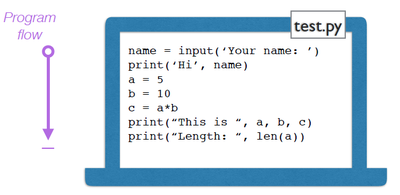 | 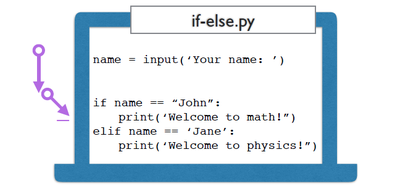 |

**Quick check:** one line of `test.py` (left) would crash if you ran it. Which one, and why?

<details><summary>Answer</summary>

The last one: `len(a)`. `a` is the whole number `5`, and a number has no length, so Python raises a `TypeError` (Week 1 types). Also note that `print("This is ", a, b, c)` prints its items separated by spaces.

</details>

### `while` loops

```python
while condition:
    block          # repeated as long as the condition is True
```

The condition is checked **before every round**. When it becomes `False`, the program continues after the block.

In [ ]:
# ✍️ Type along: count down from 5 with a while loop, then print "Lift-off!"

<details><summary>Code from class</summary>

```python
n = 5
while n > 0:
    print(n)
    n -= 1          # without this line, n > 0 stays True for ever
print("Lift-off!")
```

</details>

**Predict:** what are `a` and `my_sum` after this loop?

In [ ]:
my_sum = 0
a = 0
while a < 10:
    my_sum += a
    a += 1
print(a, my_sum)

`a` is **10**: the loop stops as soon as `a < 10` is false. `my_sum` is **45** = 0 + 1 + … + 9.

A `while` loop is the natural choice when you **don't know in advance** how many rounds you need, for example "keep asking until the user types exit":

In [ ]:
s = ""
while s != "exit":
    s = input("Type 'exit' to leave the while loop: ")
print("Bye!")

### Infinite loops

If the condition never becomes `False`, the loop never ends. Here `a` only grows, so `a > 0` is always true:

```python
a = 10
while a > 0:
    a += 1
```

Don't run this one as it is. If a cell keeps running, press the **stop** button (■) next to it, or use **Runtime → Interrupt execution** in Colab.

### `break`: leave the loop now

`break` stops the loop at once, and the program continues after it. These two loops do the same thing:

```text
# the condition in the header         # while True with break
a = 0                                  a = 0
while a < 4:                           while True:
    print(a, end=" ")                      print(a, end=" ")
    a += 1                                 a += 1
                                           if a >= 4:
                                               break
```

Prefer a clear condition in the header when you can; `break` helps when the check is more complicated, or as a safety limit.

Here is the infinite loop again, now with a safety limit. What will it print?

In [ ]:
a = 10
while a > 0:
    a += 1
    if a > 1000:        # safety limit
        break
print("Stopped at", a)

`Stopped at 1001`: the loop runs until the `break` and then continues with the line after the block.

### `continue`: skip to the next round

`continue` skips the **rest of the block** for this round only; the loop itself goes on.

**Predict:** what does this print?

In [ ]:
a = 0
while a < 10:
    a += 1
    if a % 2 == 0:
        continue
    print(a, end=" ")

`1 3 5 7 9`: for even numbers the `print` is skipped.

**Quick check:** what would happen if `a += 1` were moved to the **end** of the block, after the `print`?

<details><summary>Answer</summary>

An infinite loop. In the first round `a` is `0`, which is even, so `continue` jumps back to the header **before** `a` is increased. `a` stays `0` for ever. When you use `continue` in a `while` loop, update the loop variable first.

</details>

### Counting attempts

`while`, `if` and `break` together: the password program, now with up to three attempts and a counter.

**Before we run this:** how many wrong passwords does the loop accept? If your second attempt is `secret`, what is printed at the end?

In [ ]:
failed_attempts = 0
while failed_attempts < 3:
    password = input("Enter your password: ")
    if password == "supersecret":
        print("Administrator Access Granted")
        break
    elif password == "secret":
        print("Guest Access Granted")
        break
    else:
        print("Access Denied")
        failed_attempts += 1
print("Failed attempts:", failed_attempts)

Three wrong passwords end the loop through its condition; a right one ends it through `break`. With `secret` on the second try you see `Guest Access Granted` and `Failed attempts: 1`.

**Your turn:** `rain_mm` holds a week of daily rainfall. Use a `while` loop to add up the days one at a time, **until the total is more than 10 mm**. Print how many days that took and the total.

*Hint:* you need two variables, a position `day` and a running `total`. Also stop at the end of the list, in case it never rains enough.

In [ ]:
rain_mm = [0.0, 2.4, 11.8, 0.2, 0.0, 6.6, 3.0]   # Mon to Sun
# your code here

<details><summary>Answer</summary>

```python
day = 0
total = 0
while total <= 10 and day < len(rain_mm):
    total += rain_mm[day]
    day += 1
print(day, "days,", round(total, 1), "mm")      # 3 days, 14.2 mm
```

`day < len(rain_mm)` is the safety condition: without it, a dry week would run past the end of the list (`IndexError`).

</details>

### `for` loops

A `for` loop runs its block **once for every item** of an **iterable**: a string, a list, a tuple, a dictionary, or a `range`.

```python
for item in iterable:
    block
```

A `while` loop checks a condition before every round; a `for` loop simply takes the next item until there are none left.

In [ ]:
for letter in "Hello":
    print(letter)

### Counting with `range()`

`range()` gives a **range object, an iterable sequence of numbers**. The numbers are produced as the loop needs them; `list()` shows them all at once. As with slicing, `stop` is **not** included.

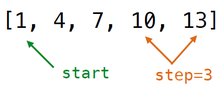

| Call | `list(...)` gives |
|---|---|
| `range(stop)` | `range(4)` → `[0, 1, 2, 3]` |
| `range(start, stop)` | `range(3, 8)` → `[3, 4, 5, 6, 7]` |
| `range(start, stop, step)` | `range(10, 20, 4)` → `[10, 14, 18]` |

What does `list(range(5, 0))` give? And the second loop?

In [ ]:
print(list(range(5, 0)))
for i in range(10, 0, -1):
    print(i, end=" ")

An **empty** list: counting up from 5 never reaches 0. To count **down**, give a negative step: `range(10, 0, -1)` is the countdown again, this time with `for`.

Change the cell to count down from 10 in steps of 2.

`range(len(...))` loops over **positions**, so the flow keeps jumping back up to the `for` line:

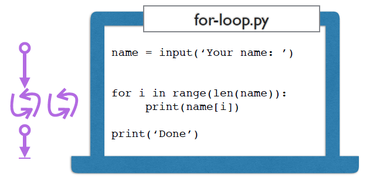

`break` and `continue` work in `for` loops exactly as in `while` loops:

In [ ]:
alphabet = "abcdefghijklmnopqrstuvwxyz"
for letter in alphabet:
    if letter == "o":
        break
    print(letter, end=" ")

The loop stops at `o`, so `a` to `n` are printed. `if letter >= "o": continue` would print the same letters, but would still look at the rest of the alphabet.

**Discuss:** `while` or `for`? Which loop fits each task, and why?
1. Print every day of the week from a list.
2. Keep asking for a password until it is right.
3. Count down from 10 to 1.
4. Read a sensor value again and again until it goes above a threshold.

<details><summary>Answer</summary>

1. **`for`**: one round per item of the list.
2. **`while`**: you don't know how many attempts it will take.
3. **`for`** with `range(10, 0, -1)`: a known number of rounds (a `while` with a counter also works, but needs more care).
4. **`while`**: the stopping point depends on the data.

Rule of thumb: `for` when you know the items or the number of rounds; `while` when you stop on a condition.

</details>

### Tracing practice

**Predict:** work out each output on paper first, then open the answer.

**Card 1**
```python
n = 1
steps = 0
while n < 50:
    n = n * 3
    steps += 1
print(n, steps)
```

<details><summary>Answer</summary>

`81 4`. `n` goes 1 → 3 → 9 → 27 → 81. The check `n < 50` happens only at the top, so `n` ends **above** 50.

</details>

**Card 2**
```python
total = 0
for i in range(1, 6):
    if i == 3:
        continue
    total += i
print(total)
```

<details><summary>Answer</summary>

`12` = 1 + 2 + 4 + 5. `range(1, 6)` stops before 6, and `continue` skips adding 3.

</details>

### Takeaways: repeating

* `while condition:` repeats as long as the condition is true; something in the block must eventually make it false.
* `break` leaves the loop; `continue` skips to the next round.
* `for item in iterable:` runs once per item; `range(start, stop, step)` is an iterable sequence of numbers, with `stop` excluded.
* Choose `for` for a known set of items, `while` for "until something happens".

## Hour 3 · Looping over data and designing a program

### Strings, lists and tuples are iterable

Every sequence from Weeks 1 and 2 can be looped over directly.

**Predict:** how many lines does this print?

In [ ]:
for letter in "Cardiff Bay":
    if letter in "aeiou":
        print(f"Letter {letter} is a vowel")

Three: `a`, `i`, `a`. Membership (`in`) and a loop together. (`y` is not in `"aeiou"`, and an upper-case vowel would not be either.)

### A week of temperatures

In Week 2 you used `max()` and `len()` on a list. A loop lets you ask **any** question of every item, one at a time, while you keep a running result.

In [ ]:
# ✍️ Type along: the warmest day and the number of warm days (15 °C or more), with one loop
temps = [14.5, 16.0, 12.5, 18.5, 17.0, 11.5, 15.0]   # daily maximum, Mon to Sun, °C

<details><summary>Code from class</summary>

```python
temps = [14.5, 16.0, 12.5, 18.5, 17.0, 11.5, 15.0]
warmest = temps[0]          # start with the first value
warm_days = 0               # a counter starts at 0
for t in temps:
    if t > warmest:
        warmest = t
    if t >= 15:
        warm_days += 1
print(warmest, warm_days)   # 18.5 4
print(max(temps))           # the built-in agrees
```

</details>

### Items or positions?

Three loops that print every item of a list:

```text
# over the items     # over the positions         # with while
for item in t:       for i in range(len(t)):      i = 0
    print(item)          print(t[i])              while i < len(t):
                                                      print(t[i])
                                                      i += 1
```

The first is the simplest. You need the position `i` when you look something up in **another** list at the same position, for example the day that belongs to a temperature.

**Before we run this:** which days will be printed?

In [ ]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
temps = [14.5, 16.0, 12.5, 18.5, 17.0, 11.5, 15.0]
for i in range(len(days)):
    if temps[i] >= 17:
        print(days[i], temps[i])

Thursday and Friday: `i` picks the same position in both lists.

### Looping over a dictionary

There are three ways to loop over a dictionary: over its **keys** (the default), its **values**, or its **(key, value) items**.

**Predict:** does `for city in pop:` give the city names or the populations?

In [ ]:
pop = {"Cardiff": 362400, "Swansea": 238500, "Newport": 159600}   # ONS Census 2021, rounded
for city in pop:                  # the same as: for city in pop.keys()
    print(city)
for people in pop.values():
    print(people)

The names: a plain loop over a dictionary gives the **keys**, just as `in` checks the keys. `.items()` gives both, as `(key, value)` tuples that you can unpack (Week 2):

In [ ]:
pop = {"Cardiff": 362400, "Swansea": 238500, "Newport": 159600}
for city, people in pop.items():
    print(f"{city} has {people} people")

### Nested loops

A loop inside a loop. For a nested list (Week 2), the **outer** loop takes each inner list and the **inner** loop takes each item of it.

**Predict:** how many lines of output, and what is on the last one?

In [ ]:
nl = [[1, 2, 3], ["a", "b", "c"], [True, False]]
for outer in nl:
    for item in outer:
        print(item, end=" ")
    print()                       # a new line after each inner list

Three lines, one per inner list; the last is `True False`. The empty `print()` belongs to the **outer** loop (look at its indentation), so it runs once per row.

### List comprehensions

A very common loop builds a new list from an old one. What will `"a" * 3` be?

In [ ]:
a = [10, "a", 3, 1]
a3 = []
for x in a:
    a3.append(x * 3)
print(a3)
print([x * 3 for x in a])         # the same, in one line

Both give `[30, 'aaa', 9, 3]` (repeating a string three times gives `'aaa'`). The second line is a **list comprehension**:

```python
new_list = [expression for item in iterable]                 # one new item per item
new_list = [expression for item in iterable if condition]    # only the items that pass
```

It loops over the iterable, applies the expression to each item, and stores the results in a new list. With `if`, it **filters**: only items that pass the condition are kept.

In [ ]:
numbers = [1, 100, 200, -30]
print([-n for n in numbers])
print([x ** 2 for x in range(1, 10)])
print([task + "-done" for task in ["homework", "shopping", "cleaning"]])
print([x for x in [10, 1, -3, 100, 5] if x < 10])

**Your turn:** with one list comprehension each:
1. `temps_f`: the temperatures in Fahrenheit (°F = °C × 9 / 5 + 32), rounded to 1 decimal place;
2. `warm`: only the temperatures of 15 °C or more;
3. `big_cities`: the names of the cities with more than 200000 people.

In [ ]:
temps = [14.5, 16.0, 12.5, 18.5, 17.0, 11.5, 15.0]
pop = {"Cardiff": 362400, "Swansea": 238500, "Newport": 159600}
# your code here

<details><summary>Answer</summary>

```python
temps_f = [round(t * 9 / 5 + 32, 1) for t in temps]
warm = [t for t in temps if t >= 15]
big_cities = [city for city, people in pop.items() if people > 200000]
print(temps_f)      # [58.1, 60.8, 54.5, 65.3, 62.6, 52.7, 59.0]
print(warm)         # [16.0, 18.5, 17.0, 15.0]
print(big_cities)   # ['Cardiff', 'Swansea']
```

</details>

### Tracing cards

**Predict:** write down the output of each card before you open the answer. To check, paste a card into the empty cell below and run it.

**Card 3**
```python
word = "loop"
result = ""
for letter in word:
    result = letter + result
print(result)
```

<details><summary>Answer</summary>

`pool`. Each letter is put in **front** of what is already there: `l` → `ol` → `ool` → `pool`. The word is reversed (Week 1 did the same with `word[::-1]`).

</details>

**Card 4**
```python
for i in range(1, 4):
    for j in range(1, 4):
        if j > i:
            break
        print(i, j)
```

<details><summary>Answer</summary>

Six lines: `1 1`, `2 1`, `2 2`, `3 1`, `3 2`, `3 3`. `break` leaves only the **inner** loop; the outer loop carries on with the next `i`.

</details>

**Card 5**
```python
stock = {"tea": 0, "milk": 2, "bread": 0, "jam": 5}
empty = [item for item in stock if stock[item] == 0]
print(empty, len(stock) - len(empty))
```

<details><summary>Answer</summary>

`['tea', 'bread'] 2`. Looping over a dictionary gives its keys, and `stock[item]` looks up each value. The keys keep their insertion order.

</details>

**Card 6**
```python
a, b = 0, 1
while b < 20:
    a, b = b, a + b
print(a, b)
```

<details><summary>Answer</summary>

`13 21`. Each round, the pair moves on: (0, 1) → (1, 1) → (1, 2) → (2, 3) → (3, 5) → (5, 8) → (8, 13) → (13, 21). The right-hand side is worked out **before** the names are re-bound, so `a + b` uses the old values. These are the Fibonacci numbers.

</details>

In [ ]:
# Paste a tracing card here to check your answer

### From idea to program

Week 1 introduced **pseudocode**: the step between an idea and real code, written for people rather than for a computer. Each line of good pseudocode turns into one or a few lines of Python.

<img alt="An idea becomes pseudocode, and the pseudocode becomes real Python code; Python is a high-level language built on lower layers" src="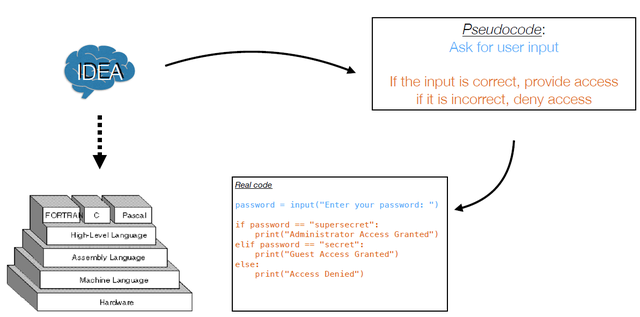">

### The lab program: Guess My Number

What does this program do? The numbers after each prompt are what the **player** typed.

```text
Welcome to 'Guess My Number'!

I am thinking of a number between 1 and 100.
Try to guess it in as few attempts as possible.

Take a guess: 78
Higher ...
Take another guess: 90
Higher ...
Take another guess: 98
Higher ...
Take another guess: 99
Higher ...
Take another guess: 100
You guessed it! The number was 100.
It took you 5 attempts.
```

A first sketch of the pseudocode:

```text
Pick a random number
While the player has not guessed the right number
    Let the player guess
    Give the player a clue if it is a wrong guess
Congratulate the player
```

**Discuss:** which of today's tools does each line need? And what is missing from the sketch if we also want to print *"It took you 5 attempts"*?

<details><summary>Answer</summary>

* **Pick a random number:** a ready-made function, `random.randint(1, 100)` (modules are next week's topic).
* **While … not guessed:** a `while` loop with the Boolean expression `guess != the_number`.
* **Give a clue:** `if`/`else` with `>` (`Lower ...` or `Higher ...`).
* **Count the attempts:** a counter that starts at 1 and grows by 1 with every new guess, as in the password loop.

</details>

A more detailed version, closer to the code:

```text
Welcome the player and give some instructions
Pick a number between 1 and 100
Ask the player for a guess
Set the number of guesses to 1
While the player's guess is wrong
    If the player's guess is larger than the number
        Tell the player to guess lower
    Otherwise
        Tell the player to guess higher
    Get a new guess from the player
    Increment the number of guesses by 1
Congratulate the player
Tell the number of guesses they took
```
<details><summary>The program (Guess My Number 1.0)</summary>

```python
import random
print("Welcome to 'Guess My Number'!")
print("\nI am thinking of a number between 1 and 100.")
print("Try to guess it in as few attempts as possible.\n")

# set the initial values
the_number = random.randint(1, 100)
guess = int(input("Take a guess: "))
attempts = 1

# guess loop
while guess != the_number:
    if guess > the_number:
        print("Lower ...")
    else:
        print("Higher ...")
    guess = int(input("Take another guess: "))
    attempts += 1

# congratulate the player
print(f"You guessed it! The number was {the_number}.")
print(f"It took you {attempts} attempts.")
```

Match each block to a line of the detailed pseudocode. In the lab you build this program yourself, one step at a time, and then extend it.

</details>

### Takeaways: looping over data

* `for` works on every iterable: strings, lists, tuples, `range` and dictionaries (keys by default; `.values()`, `.items()`).
* A running result (`warmest`, a counter, a total) is set **before** the loop and updated **inside** it.
* Nested loops: the inner loop runs completely for each round of the outer loop; `break` leaves only the innermost loop.
* `[expression for item in iterable if condition]` builds a new list in one line.
* Idea → pseudocode → code: write the steps in words first, then translate each one.

## Transition to the lab

**You now know** how to make decisions with Boolean expressions and `if`/`elif`/`else`, how to repeat code with `while` and `for`, and how to go from pseudocode to a program.

**The lab** (`W03_lab_student.ipynb`, one hour) builds the **Guess My Number** game in small steps: pseudocode → pick a number → one guess with a hint → a loop until the guess is right → count the attempts. Each step has a checkpoint. Optional challenges add an attempt limit, protection against typing mistakes, and a version in which the computer does the guessing.

## Week 3 takeaways

* Boolean expressions (`==`, `<`, `and`, `or`, `not`, `is`, `in`) answer yes/no questions.
* `if`/`elif`/`else` chooses **one** block; indentation shows where blocks start and end.
* `while` repeats until a condition becomes false; `for` repeats once per item of an iterable; `break` and `continue` change the flow inside a loop.
* `range()` gives an iterable sequence of numbers; strings, lists, tuples and dictionaries can be looped over directly.
* List comprehensions build (and filter) lists in one line.

## Where next

**Week 4 · Functions, files and modules.** You will package code into your own **functions**: the flow jumps into the function, runs its block, and comes back. You will also read and write files, and use modules such as `random`. The Week 4 lab turns today's Guess My Number game into functions.

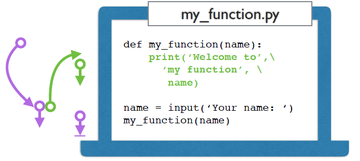

Before next week: run this notebook from top to bottom, and finish any *Your turn* you skipped.

## Optional: explore after class

**More list comprehensions.** Apply the exponential function to every whole number from -10 to 10 (inclusive). `exp` lives in the `math` module (modules are covered next week):

In [ ]:
import math
exp_values = [math.exp(x) for x in range(-10, 11)]
print(len(exp_values), round(exp_values[10], 1), round(exp_values[-1], 1))

`exp_values[10]` belongs to `x = 0`, and `exp(0)` is 1.

**A comprehension that changes nothing.** `[x for x in a]` returns a list with exactly the same items as `a`. Is it the same list? Check with `is` and `==`:

In [ ]:
a = [10, 1, -3, 100, 5]
same = [x for x in a]
print(same == a, same is a)

Equal values, but a **new** list: a comprehension is one more way to copy a list (Week 2).